### Goals:
- Understanding class imbalance and when to optimise for precision/recall.
- Handle class imbalance.

In [1]:
import pandas as pd
import numpy as np

## Imagining have an imbalance dataset (of testing)

For instant, we have a frames of e-mail, conclude 9 formal and 1 informal

In [2]:
data = [
    ["Best Regards", "formal"],
    ["Dear Venn,", "formal"],
    ["Comment-allez vous?", "formal"],
    ["I hope you consider my idea", "formal"],
    ["Would you like", "formal"],
    ["I would like to", "formal"],
    ["Let's go below zero", "informal"],
    ["No coding experience or course fees required", "formal"],
    ["We sincerely apologise for the change and any inconvenience this may cause", "formal"],
    ["Here are such suggestions...", "formal"]
]

frame = pd.DataFrame(data, columns=["content", "label"])
# Encode
frame["label"] = frame["label"].map({"formal": 0, "informal": 1})

display(frame)


,content,label
0,Best Regards,0
1,"Dear Venn,",0
2,Comment-allez vous?,0
3,I hope you consider my idea,0
4,Would you like,0
5,I would like to,0
6,Let's go below zero,1
7,No coding experience or course fees required,0
8,We sincerely apologise for the change and any ...,0
9,Here are such suggestions...,0


## Who needs machine learning to handle
Just assume that all of them are formal

In [3]:
y = frame["label"]

# Assume all are zero
y_pred = np.zeros(len(frame), dtype=int)
display(y_pred)

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

### See the "black magic"
Accuracy compute by the following formula:
$$
Accuracy = \frac{TP + TN}{Sum \space of \space predictions}
$$

In [4]:
def compute_accuracy(y, y_pred):
    # no need to handle exceptions, since just want to show the formula
    correct = sum(1 for yt, yp in zip(y, y_pred) if yt == yp)
    return correct / len(y)

display(compute_accuracy(y=y, y_pred=y_pred))

0.9

Yes ninety percent, higher than the confidence of mine in exam, with zero step of calculating. It's just a dummy model such "zero zero zero,..." told user the imbalance of dataset exactly.

**Confusion matrix** helps to reveal the complete picture.

|             | Predict 0 | Predict 1 |
| :---        |   :---:   |   :---:   |
| **Real 0**  |    TN     |    FP     |
| **Real 1**  |    FN     |    TP     |

In [5]:
from src.metric import compute_confusion_matrix, metrics_from_cm

confusion_matrix = compute_confusion_matrix(y_true=y, y_pred=y_pred, num_classes=2)
display(confusion_matrix)

array([[9, 0],
       [1, 0]])

To discover, **precision** and **recall** is conssidered

$$
Precision = \frac{TP}{TP+FP}, \space Recall = \frac{TP}{TP+FN}, \space F1 = \frac{2*Precision*Recall}{Precision \space + Recall}
$$

In [6]:
display(metrics_from_cm(confusion_matrix))

{'accuracy': np.float64(0.9),
 'precision': 0.0,
 'recall': np.float64(0.0),
 'f1': 0.0}

Deciding which metric to optimize depends entirely on the context. Keep in mind that the F1 score offers a balance between precision and recall. You should prioritize recall when missing a positive case could lead to severe consequences (such as in healthcare or cheating detection), whereas in other scenarios, you might need to focus on maximizing the number of correct predictions (to avoid false alarms).

## Addressing the class imbalance problem during training

Before sampling: Counter({np.int64(0): 3800, np.int64(1): 200})


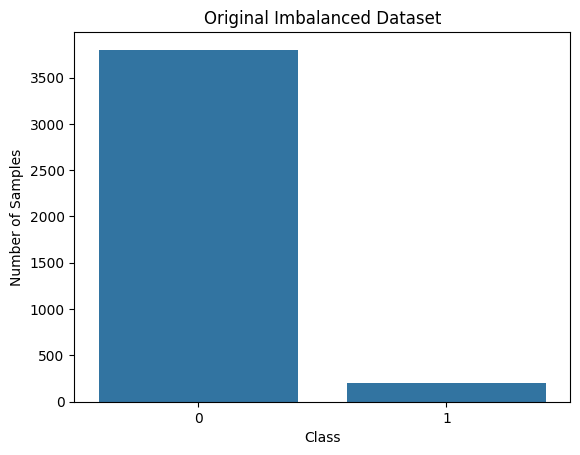

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification
from collections import Counter

# Create un imbalance dataset (ratio 95:5)
X, y = make_classification(n_samples=5000, n_features=20, n_informative=15, 
                           n_redundant=5, weights=[0.95], flip_y=0, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Before sampling:", Counter(y_train))

sns.countplot(x=y_train)
plt.title("Original Imbalanced Dataset")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.show()

### Resampling: Adding (oversampling) or removing (undersampling) 
The essence of resampling lies in balancing the number of samples across different classes. While various methods exist, their drawbacks can be summarized as follows:
- Oversampling increases the volume of data, which complicates computational processes; furthermore, when interpolation-based techniques are used to generate samples, the resulting new data may be unrealistic (i.e., "garbage" data).
- Undersampling may involve discarding too much data, potentially leading to the loss of critical information.

Before: Counter({np.int64(0): 3800, np.int64(1): 200})
After: Counter({np.int64(0): 200, np.int64(1): 200})


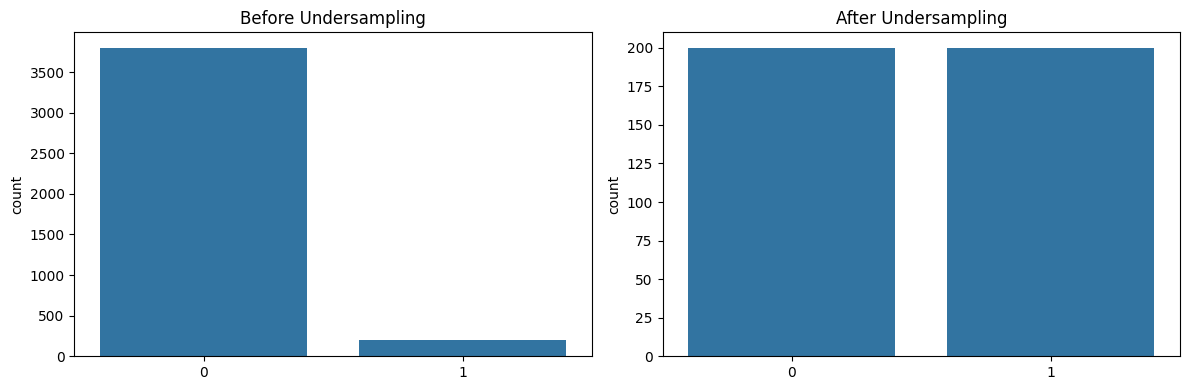

Before: Counter({np.int64(0): 3800, np.int64(1): 200})
After: Counter({np.int64(0): 3800, np.int64(1): 3800})


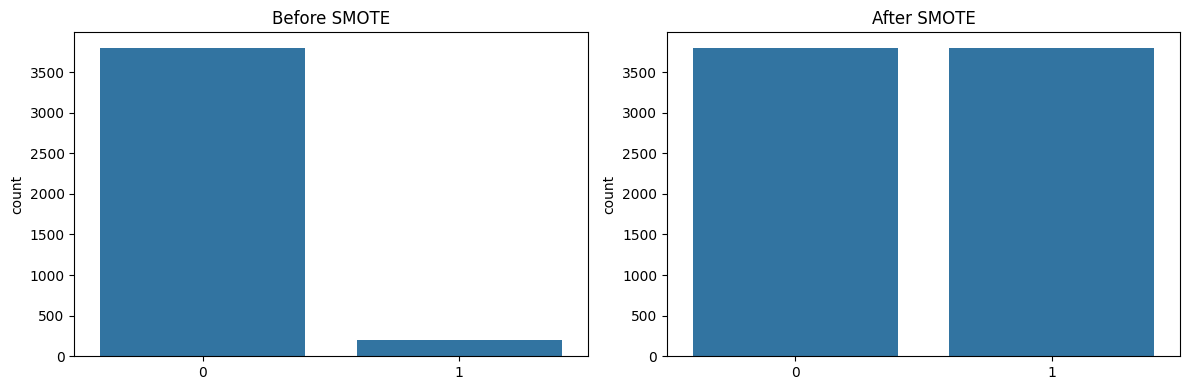

In [8]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

# Initialize
under_sampler = RandomUnderSampler(
    sampling_strategy='auto',
    random_state=42
)

# Apply undersampling
X_under, y_under = under_sampler.fit_resample(
    X_train, y_train
)

print("Before:", Counter(y_train))
print("After:", Counter(y_under))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title("Before Undersampling")

sns.countplot(x=y_under, ax=axes[1])
axes[1].set_title("After Undersampling")

plt.tight_layout()
plt.show()


smote = SMOTE(
    sampling_strategy='auto',
    random_state=42,
    k_neighbors=5
)

X_smote, y_smote = smote.fit_resample(
    X_train, y_train
)

print("Before:", Counter(y_train))
print("After:", Counter(y_smote))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title("Before SMOTE")

sns.countplot(x=y_smote, ax=axes[1])
axes[1].set_title("After SMOTE")

plt.tight_layout()
plt.show()

In instants, methods of adding or removing are not usually considered. Instead, **class weight** and *threshold** are used with greater frequency, and also demonstrates good effectiveness when applied within a specific context.

In [9]:
from sklearn.linear_model import LogisticRegression

# Class Weight model
model_weighted = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

model_weighted.fit(X_train, y_train)
y_pred_weighted = model_weighted.predict(X_test)

print(metrics_from_cm(compute_confusion_matrix(y_test, y_pred_weighted, num_classes=2)))

{'accuracy': np.float64(0.832), 'precision': np.float64(0.1958762886597938), 'recall': np.float64(0.76), 'f1': np.float64(0.3114754098360656)}


### My takes: In instance, the method considered is thresholding, personally. 
Specifically, instead of returning a single label as the result, the model outputs a distribution—for instance, indicating that "there is a 40% probability that this example belongs to the `alpha` class." This allows for the calculation of precision and recall across as many thresholds as possible within the range $[0, 1]$, enabling the selection of a threshold that aligns with specific requirements.

In [10]:
# Obtain predicted probabilities
y_proba = model_weighted.predict_proba(X_test)[:, 1]

# Apply a custom threshold
threshold = 0.3

y_pred_custom = (y_proba >= threshold).astype(int)

# Evaluate
cm = compute_confusion_matrix(
    y_test,
    y_pred_custom,
    num_classes=2
)

display(metrics_from_cm(cm))

{'accuracy': np.float64(0.725),
 'precision': np.float64(0.1382636655948553),
 'recall': np.float64(0.86),
 'f1': np.float64(0.23822714681440443)}

In [11]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

for threshold in thresholds:
    y_pred = (y_proba >= threshold).astype(int)

    cm = compute_confusion_matrix(
        y_test,
        y_pred,
        num_classes=2
    )

    metrics = metrics_from_cm(cm)

    print(
        f"Threshold: {threshold:.1f} | "
        f"Precision: {metrics['precision']:.3f} | "
        f"Recall: {metrics['recall']:.3f} | "
        f"F1: {metrics['f1']:.3f}"
    )

Threshold: 0.1 | Precision: 0.083 | Recall: 0.960 | F1: 0.154
Threshold: 0.2 | Precision: 0.108 | Recall: 0.920 | F1: 0.194
Threshold: 0.3 | Precision: 0.138 | Recall: 0.860 | F1: 0.238
Threshold: 0.4 | Precision: 0.166 | Recall: 0.820 | F1: 0.276
Threshold: 0.5 | Precision: 0.196 | Recall: 0.760 | F1: 0.311
Threshold: 0.6 | Precision: 0.241 | Recall: 0.680 | F1: 0.356
Threshold: 0.7 | Precision: 0.313 | Recall: 0.620 | F1: 0.416
